# Downloading the dataset
We are downloading the dataset from Hugging Face using the `datasets` library.

In [1]:
from datasets import load_dataset

ds = load_dataset("mapo80/DocCornerDataset")

/home/hunterx/ml-venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Visualizing the dataset
We are visualizing the dataset using the `matplotlib` library. We are visualizing multiple random samples from the dataset.

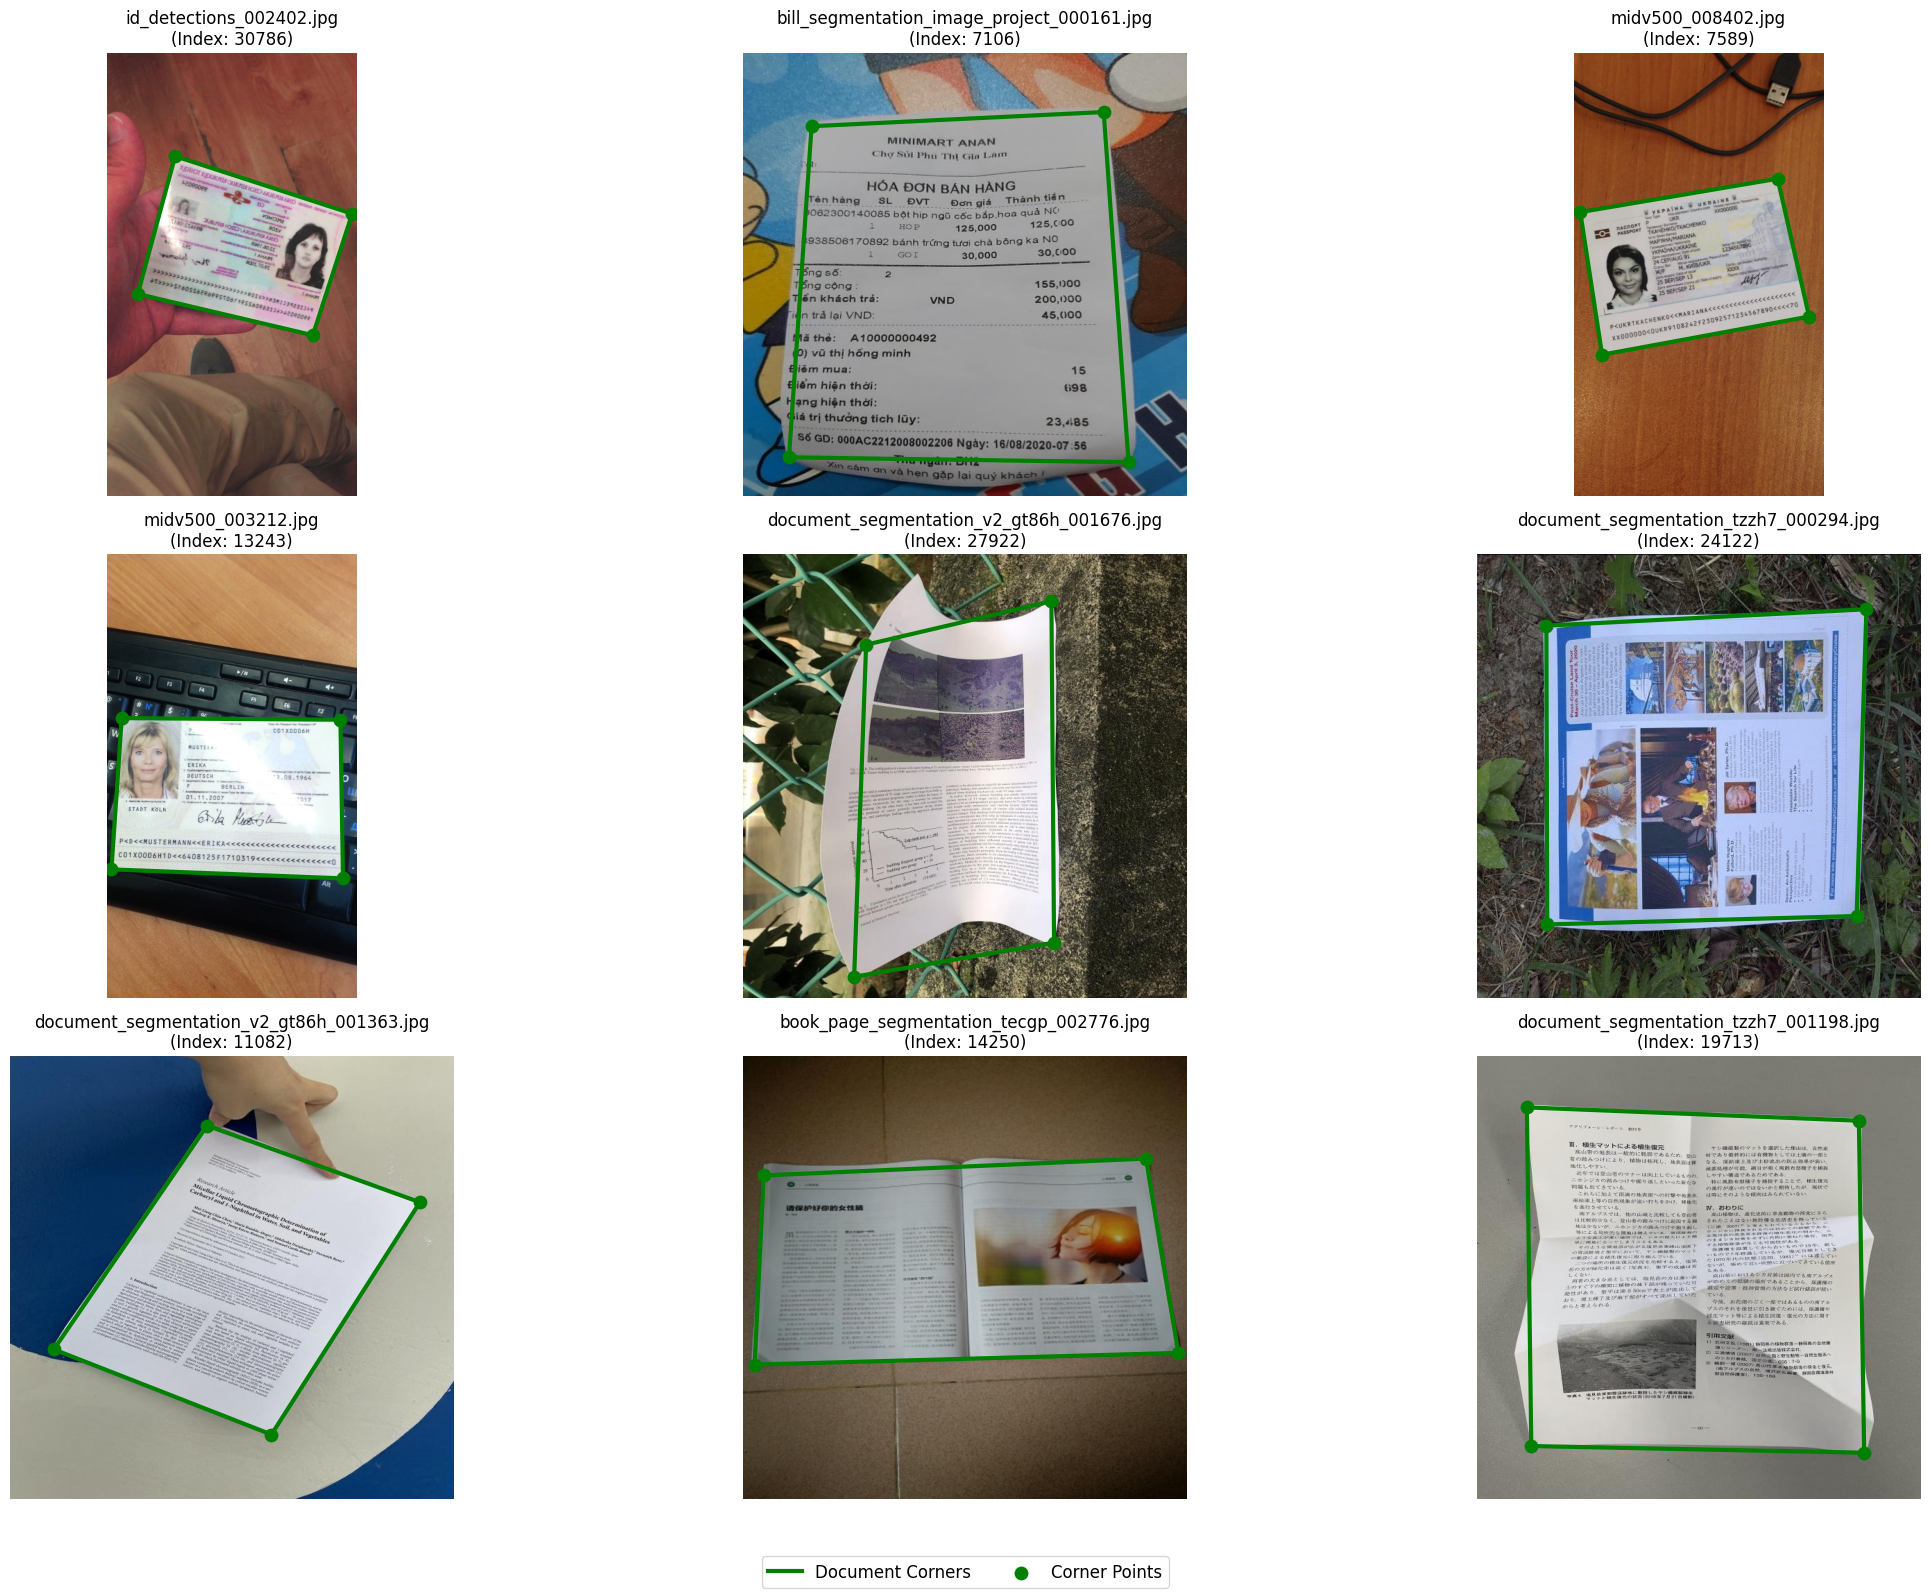

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import random

def visualize_multiple_random_samples(dataset, split='train', num_samples=9):
    samples = dataset[split]
    
    fig, axes = plt.subplots(3, 3, figsize=(24, 16))
    axes = axes.flatten()
    
    for i in range(num_samples):
        # Pick a random index, ensuring we pick an image that ACTUALLY contains a document (is_negative == False)
        while True:
            idx = random.randint(0, len(samples) - 1)
            sample = samples[idx]
            if not sample['is_negative']:
                break
                
        image = sample['image']
        width, height = image.size
        ax = axes[i]
        
        ax.imshow(image)
        
        # The coordinates in the dataset are normalized between 0 and 1!
        # They need to be multiplied by width and height to map to the image's pixel dimensions.
        corners_x = [
            sample['corner_tl_x'] * width, 
            sample['corner_tr_x'] * width, 
            sample['corner_br_x'] * width, 
            sample['corner_bl_x'] * width, 
            sample['corner_tl_x'] * width
        ]
        corners_y = [
            sample['corner_tl_y'] * height, 
            sample['corner_tr_y'] * height, 
            sample['corner_br_y'] * height, 
            sample['corner_bl_y'] * height, 
            sample['corner_tl_y'] * height
        ]
        
        # Plot the exact four corners
        ax.plot(corners_x, corners_y, color='green', linestyle='-', linewidth=3, label='Document Corners' if i == 0 else '', zorder=2)
        ax.scatter(corners_x[:-1], corners_y[:-1], c='green', edgecolors='green', s=80, zorder=3, label='Corner Points' if i == 0 else '')
        
        ax.set_title(f"{sample['filename']}\n(Index: {idx})")
        ax.axis('off')
        
    # Add a single legend to the figure
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower center', ncol=2, fontsize='large')
    
    plt.tight_layout(rect=[0, 0.05, 1, 1]) # Leave space for the legend
    plt.show()

# Visualize 6 random positive samples from the training set
visualize_multiple_random_samples(ds, split='train', num_samples=9)

# Preparing the dataset for training
We are preparing the dataset for training the model. We are creating a TensorFlow dataset from the Hugging Face dataset. We are applying data augmentation and batching the dataset for training.

In [2]:
import tensorflow as tf
IMG_SIZE = 224          # Input image size
HEATMAP_SIZE = 56       # Output heatmap size
GAUSSIAN_SIGMA = 3      # Gaussian sigma for heatmap generation
BATCH_SIZE = 16
TRAIN_LIMIT = None      # None uses full dataset
VAL_LIMIT = None        # None uses full dataset
TEST_LIMIT = None       # None uses full dataset

def create_gaussian_heatmap(center_x, center_y, size=HEATMAP_SIZE, sigma=GAUSSIAN_SIGMA):
    """Create a Gaussian heatmap for a single corner."""
    x = np.arange(0, size, 1, float)
    y = np.arange(0, size, 1, float)[:, np.newaxis]

    center_x_px = center_x * size
    center_y_px = center_y * size

    heatmap = np.exp(-((x - center_x_px)**2 + (y - center_y_px)**2) / (2 * sigma**2))
    return heatmap.astype(np.float32)

def create_tf_dataset(dataset_dict, split, max_samples=None):
    """
    Create a TensorFlow dataset generator for image-heatmap pairs with document presence labels.
    """
    split_name = 'train' if split == 'train' else ('validation' if split == 'validation' else 'test')
    samples = dataset_dict[split_name]
    
    for idx, sample in enumerate(samples):
        if max_samples is not None and idx >= max_samples:
            break

        is_negative = sample.get('is_negative', False)

        image = sample['image'].convert('RGB')

        # IMPORTANT: keep geometry unchanged unless corner coordinates are transformed too.
        # Photometric augmentation is safe and does not change corner labels.
        if split == 'train':
            import PIL.ImageEnhance as ImageEnhance
            brightness_factor = np.random.uniform(0.8, 1.2)
            contrast_factor = np.random.uniform(0.8, 1.2)
            image = ImageEnhance.Brightness(image).enhance(brightness_factor)
            image = ImageEnhance.Contrast(image).enhance(contrast_factor)

        image = image.resize((IMG_SIZE, IMG_SIZE))
        image_array = np.array(image, dtype=np.float32) / 255.0

        heatmap = np.zeros((HEATMAP_SIZE, HEATMAP_SIZE, 4), dtype=np.float32)
        doc_present = 1.0 if not is_negative else 0.0

        if not is_negative:
            corners = np.array([
                sample['corner_tl_x'], sample['corner_tl_y'],
                sample['corner_tr_x'], sample['corner_tr_y'],
                sample['corner_br_x'], sample['corner_br_y'],
                sample['corner_bl_x'], sample['corner_bl_y']
            ], dtype=np.float32)

            for i in range(4):
                x_norm = corners[2*i]
                y_norm = corners[2*i + 1]
                heatmap[:, :, i] = create_gaussian_heatmap(x_norm, y_norm)
        else:
            # Keep negative samples in the dataset; their target is an empty heatmap.
            heatmap.fill(0.0)

        yield tf.convert_to_tensor(image_array), (tf.convert_to_tensor(heatmap), tf.constant(doc_present, dtype=tf.float32))

output_signature = (
    tf.TensorSpec(shape=(IMG_SIZE, IMG_SIZE, 3), dtype=tf.float32),
    (
        tf.TensorSpec(shape=(HEATMAP_SIZE, HEATMAP_SIZE, 4), dtype=tf.float32),
        tf.TensorSpec(shape=(), dtype=tf.float32)
    )
)

print("Preparing training dataset...")
train_ds = (tf.data.Dataset.from_generator(
    lambda: create_tf_dataset(ds, "train", max_samples=TRAIN_LIMIT),
    output_signature=output_signature
)
    .batch(BATCH_SIZE)
    .repeat()  # Required when using steps_per_epoch across multiple epochs
    .prefetch(tf.data.AUTOTUNE))

print("Preparing validation dataset...")
val_ds = (tf.data.Dataset.from_generator(
    lambda: create_tf_dataset(ds, "validation", max_samples=VAL_LIMIT),
    output_signature=output_signature
)
    .batch(BATCH_SIZE)
    .repeat()  # Required when using validation_steps across multiple epochs
    .prefetch(tf.data.AUTOTUNE))

print("Preparing test dataset...")
test_ds = (tf.data.Dataset.from_generator(
    lambda: create_tf_dataset(ds, "test", max_samples=TEST_LIMIT),
    output_signature=output_signature
)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE))
print("Datasets ready!")

I0000 00:00:1778617919.434668     845 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


Preparing training dataset...
Preparing validation dataset...
Preparing test dataset...
Datasets ready!


I0000 00:00:1778617926.917862     845 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1763 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


# Visualizing the dataset after processing

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def show_image_with_combined_heatmap(tf_dataset, num_samples=9):
    """
    Show only:
    - Preprocessed image
    - Combined heatmap overlaid on the image
    """

    # Get one batch from the dataset
    for batch_images, (batch_heatmaps, batch_doc_present) in tf_dataset.take(1):
        break

    num_samples = min(num_samples, batch_images.shape[0])

    rows = int(np.ceil(np.sqrt(num_samples)))
    cols = int(np.ceil(num_samples / rows))

    fig, axes = plt.subplots(rows, cols, figsize=(6 * cols, 6 * rows))
    axes = np.array(axes).reshape(-1)

    for i in range(num_samples):
        image = batch_images[i].numpy()
        heatmaps = batch_heatmaps[i].numpy()
        doc_present = batch_doc_present[i].numpy()

        ax = axes[i]

        # Show preprocessed image
        ax.imshow(image)

        if doc_present > 0.5:
            # Combine all 4 corner heatmaps into one
            combined_heatmap = np.max(heatmaps, axis=-1)

            # Overlay heatmap on top of image
            ax.imshow(
                combined_heatmap,
                cmap='jet',
                alpha=0.5,  # transparency
                extent=[0, IMG_SIZE, IMG_SIZE, 0]
            )

        ax.set_title(f"Sample {i + 1}")
        ax.axis("off")

    # Hide unused axes
    for j in range(num_samples, len(axes)):
        axes[j].axis("off")

    plt.tight_layout()
    plt.show()


# Usage
show_image_with_combined_heatmap(train_ds, num_samples=9)

# Model Defination 

In [3]:
import tensorflow as tf
from tensorflow.keras import layers

class DocCornerNet(tf.keras.Model):
    def __init__(self, input_shape=(224, 224, 3), alpha=0.75, decoder_filters=64, heatmap_size=56):
        super().__init__()
        self.input_shape_ = input_shape
        self.heatmap_size = heatmap_size

        base = tf.keras.applications.MobileNetV3Small(
            input_shape=input_shape,
            alpha=alpha,
            include_top=False,
            weights="imagenet",
            include_preprocessing=False,
        )
        base.trainable = False
        self.backbone = base

        self.upsample_blocks = []
        for i in range(3):
            self.upsample_blocks.append(tf.keras.Sequential([
                layers.UpSampling2D(size=(2,2), interpolation="bilinear"),
                layers.Conv2D(decoder_filters // (2 ** max(0, i-1)), 3, padding="same", activation="relu"),
                layers.BatchNormalization(),
            ]))

        self.refine_conv = layers.Conv2D(decoder_filters // 2, 3, padding="same", activation="relu")
        self.refine_bn = layers.BatchNormalization()
        self.heatmap_head = layers.Conv2D(4, 1, padding="same", activation="sigmoid", name="heatmap_head")

        self.presence_pool = layers.GlobalAveragePooling2D()
        self.presence_dense = layers.Dense(64, activation="relu")
        self.presence_out = layers.Dense(1, activation="sigmoid", name="presence_out")

    def call(self, inputs, training=False):
        x = inputs
        features = self.backbone(x, training=False)
        y = features
        for blk in self.upsample_blocks:
            y = blk(y, training=training)
        y = self.refine_conv(y)
        y = self.refine_bn(y, training=training)
        y = tf.image.resize(y, (self.heatmap_size, self.heatmap_size), method="bilinear")
        heatmaps = self.heatmap_head(y)
        pooled = self.presence_pool(features)
        p = self.presence_dense(pooled)
        presence = self.presence_out(p)
        presence = tf.squeeze(presence, axis=-1)
        return heatmaps, presence

    @classmethod
    def from_config(cls, config):
        # Filter out keys that the constructor does not accept (e.g., 'trainable', 'dtype')
        cfg = dict(config)
        cfg.pop('trainable', None)
        cfg.pop('dtype', None)
        return cls(**cfg)

# Instantiate and run a quick forward pass to verify shapes
model = DocCornerNet(input_shape=(IMG_SIZE, IMG_SIZE, 3), heatmap_size=HEATMAP_SIZE)


# Load the pretrained weights

In [4]:
import os
import tensorflow as tf

# Load the saved model
model_dir = "models"
model_path = os.path.join(model_dir, "doccornernet_model.keras")

if os.path.exists(model_path):
    model = tf.keras.models.load_model(model_path, custom_objects={'DocCornerNet': DocCornerNet})
    print(f"Model loaded from: {model_path}")
else:
    print(f"Model not found at: {model_path}")

Model loaded from: models/doccornernet_model.keras


/home/hunterx/ml-venv/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:798: UserWarning: Skipping variable loading for optimizer 'adam', because it has 46 variables whereas the saved optimizer has 322 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


# Training

In [5]:
import numpy as np
import tensorflow as tf

EPOCHS = 10

# Calculate dataset sizes - use full dataset if limits are None
train_count = len(ds["train"]) if TRAIN_LIMIT is None else min(len(ds["train"]), TRAIN_LIMIT)
val_count = len(ds["validation"]) if VAL_LIMIT is None else min(len(ds["validation"]), VAL_LIMIT)
test_count = len(ds["test"]) if TEST_LIMIT is None else min(len(ds["test"]), TEST_LIMIT)

print(f"Training samples: {train_count}")
print(f"Validation samples: {val_count}")
print(f"Test samples: {test_count}")

steps_per_epoch = max(1, int(np.ceil(train_count / BATCH_SIZE)))
validation_steps = max(1, int(np.ceil(val_count / BATCH_SIZE)))
test_steps = max(1, int(np.ceil(test_count / BATCH_SIZE)))

print(f"Steps per epoch: {steps_per_epoch}")
print(f"Validation steps: {validation_steps}")
print(f"Test steps: {test_steps}")

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=[
        tf.keras.losses.MeanSquaredError(),
        tf.keras.losses.BinaryCrossentropy(),
    ],
    loss_weights=[1.0, 0.5],
    metrics=[
        [tf.keras.metrics.MeanAbsoluteError(name="heatmap_mae")],
        [
            tf.keras.metrics.BinaryAccuracy(name="presence_acc"),
            tf.keras.metrics.AUC(name="presence_auc"),
        ],
    ],
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
    ),
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    steps_per_epoch=steps_per_epoch,
    validation_steps=validation_steps,
    callbacks=callbacks,
    verbose=1,
 )

print("Evaluating on test set...")
test_metrics = model.evaluate(test_ds, steps=test_steps, return_dict=True)
for name, value in test_metrics.items():
    print(f"{name}: {value:.4f}")

Training samples: 32968
Validation samples: 8645
Test samples: 6652
Steps per epoch: 2061
Validation steps: 541
Test steps: 416
Epoch 1/10


I0000 00:00:1778617962.129962     845 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.
I0000 00:00:1778617970.151116    1482 service.cc:153] XLA service 0x7fb78c0341e0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1778617970.151163    1482 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 3050 Laptop GPU, Compute Capability 8.6 (Driver: 13.2.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.21.1)
I0000 00:00:1778617970.511925    1482 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1778617972.844224    1482 cuda_dnn.cc:461] Loaded cuDNN version 92101
I0000 00:00:1778617972.988378    1482 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_15916__.199
I0000 00:00:1778618000.089168    1482 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the pro

2060/2061 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - binary_crossentropy_loss: 7.6331e-04 - heatmap_mae: 0.0036 - loss: 6.9448e-04 - mean_squared_error_loss: 3.1283e-04 - presence_acc: 0.9998 - presence_auc: 0.9997

I0000 00:00:1778620180.323786    1482 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_15916__.199


2061/2061 ━━━━━━━━━━━━━━━━━━━━ 2540s 1s/step - binary_crossentropy_loss: 7.3568e-04 - heatmap_mae: 0.0036 - loss: 6.8792e-04 - mean_squared_error_loss: 3.1998e-04 - presence_acc: 0.9998 - presence_auc: 0.9997 - val_binary_crossentropy_loss: 0.0022 - val_heatmap_mae: 0.0038 - val_loss: 0.0015 - val_mean_squared_error_loss: 3.9584e-04 - val_presence_acc: 0.9994 - val_presence_auc: 0.9990 - learning_rate: 0.0010
Epoch 2/10
2061/2061 ━━━━━━━━━━━━━━━━━━━━ 2513s 1s/step - binary_crossentropy_loss: 0.0011 - heatmap_mae: 0.0035 - loss: 8.5300e-04 - mean_squared_error_loss: 3.0640e-04 - presence_acc: 0.9996 - presence_auc: 0.9997 - val_binary_crossentropy_loss: 6.7280e-04 - val_heatmap_mae: 0.0038 - val_loss: 7.1787e-04 - val_mean_squared_error_loss: 3.8159e-04 - val_presence_acc: 0.9997 - val_presence_auc: 1.0000 - learning_rate: 0.0010
Epoch 3/10
2061/2061 ━━━━━━━━━━━━━━━━━━━━ 2419s 1s/step - binary_crossentropy_loss: 7.8269e-06 - heatmap_mae: 0.0034 - loss: 2.9603e-04 - mean_squared_error_lo


# Fine-tune the Backbone
Unfreeze MobileNetV3Small backbone and continue training with a low learning rate.


In [19]:

# Unfreeze the backbone
model.backbone.trainable = True

# Recompile with a much lower learning rate for fine-tuning
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),  # 10x lower than initial
    loss=[
        tf.keras.losses.MeanSquaredError(),
        tf.keras.losses.BinaryCrossentropy(),
    ],
    loss_weights=[1.0, 0.5],
    metrics=[
        [tf.keras.metrics.MeanAbsoluteError(name="heatmap_mae")],
        [
            tf.keras.metrics.BinaryAccuracy(name="presence_acc"),
            tf.keras.metrics.AUC(name="presence_auc"),
        ],
    ],
)

print("Backbone unfrozen. Starting fine-tuning with lr=1e-5...")

# Fine-tune for a few more epochs
FINETUNE_EPOCHS = 20

history_finetune = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FINETUNE_EPOCHS,
    steps_per_epoch=steps_per_epoch,
    validation_steps=validation_steps,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True,
        ),
    ],
    verbose=1,
)

print("Fine-tuning complete!")
print("Evaluating on test set after fine-tuning...")
test_metrics_finetune = model.evaluate(test_ds, steps=test_steps, return_dict=True)
for name, value in test_metrics_finetune.items():
    print(f"{name}: {value:.4f}")


Backbone unfrozen. Starting fine-tuning with lr=1e-5...
Epoch 1/20


I0000 00:00:1778683830.227676    1482 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_3113200__.199


 691/2061 ━━━━━━━━━━━━━━━━━━━━ 24:57 1s/step - binary_crossentropy_loss: 0.0020 - heatmap_mae: 0.0037 - loss: 0.0014 - mean_squared_error_loss: 4.0571e-04 - presence_acc: 0.9995 - presence_auc: 0.9995

KeyboardInterrupt: 

# Model Saving
Save the trained model for future inference and deployment.

In [12]:
import os

# Create a directory for model checkpoints if it doesn't exist
model_dir = "models"
if not os.path.exists(model_dir):
    os.makedirs(model_dir)

# Save the trained model in native Keras format (.keras)
model_path = os.path.join(model_dir, "doccornernet_model.keras")
model.save(model_path)
print(f"Model saved to: {model_path}")

# Save training history as well
import json

history_path = os.path.join(model_dir, "training_history.json")
with open(history_path, 'w') as f:
    json.dump(history.history, f, indent=4)
print(f"Training history saved to: {history_path}")

Model saved to: models/doccornernet_model.keras
Training history saved to: models/training_history.json


# Export to TFLite
Convert the trained model to TensorFlow Lite for lightweight inference.

In [18]:
import os
import tensorflow as tf

# Reuse the trained model if it is already in memory; otherwise load it from disk.
if 'model' not in globals():
    model = tf.keras.models.load_model(os.path.join(model_dir, "doccornernet_model.keras"), custom_objects={'DocCornerNet': DocCornerNet})

# Explicitly build the model with concrete input shapes before conversion
model.build(input_shape=(None, IMG_SIZE, IMG_SIZE, 3))

tflite_path = os.path.join(model_dir, "doccornernet_model_fp16.tflite")

converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.target_spec.supported_types = [tf.float16]

tflite_model = converter.convert()

with open(tflite_path, 'wb') as f:
    f.write(tflite_model)

print(f"TFLite model saved to: {tflite_path}")
print(f"TFLite model size: {len(tflite_model) / (1024 * 1024):.2f} MB")

INFO:tensorflow:Assets written to: /tmp/tmpvni8_hke/assets


INFO:tensorflow:Assets written to: /tmp/tmpvni8_hke/assets


Saved artifact at '/tmp/tmpvni8_hke'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None)
Output Type:
  Tuple[TensorSpec(shape=(None, 56, 56, 4), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.float32, name=None)]
Captures:
  140429275444816: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140429275445200: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140429275445008: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140429275444240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140429275445776: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140429275442704: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140443293955472: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140429275445968: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140429275443664: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140429275446736: Tensor

W0000 00:00:1778683643.920966     845 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1778683643.921203     845 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1778683643.922366     845 reader.cc:83] Reading SavedModel from: /tmp/tmpvni8_hke
I0000 00:00:1778683643.934174     845 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1778683643.934205     845 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmpvni8_hke
I0000 00:00:1778683644.061007     845 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1778683644.615535     845 loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmpvni8_hke
I0000 00:00:1778683644.744711     845 loader.cc:471] SavedModel load for tags { serve }; Status: success: OK. Took 822364 microseconds.


# Load TFLite Model and Predict
Load the TFLite model and run inference on test samples to visualize predictions.

In [ ]:
import os
import numpy as np
import tensorflow as tf

class TFLiteModelWrapper:
    def __init__(self, tflite_path):
        if not os.path.exists(tflite_path):
            raise FileNotFoundError(f"TFLite model not found: {tflite_path}")

        self.interpreter = tf.lite.Interpreter(model_path=tflite_path)
        self.interpreter.allocate_tensors()
        self.input_details = self.interpreter.get_input_details()
        self.output_details = self.interpreter.get_output_details()

    def predict(self, batch_images, verbose=0):
        heatmap_preds = []
        presence_preds = []
        input_index = self.input_details[0]["index"]

        for image in batch_images:
            input_tensor = np.expand_dims(image.numpy().astype(np.float32), axis=0)
            self.interpreter.set_tensor(input_index, input_tensor)
            self.interpreter.invoke()
            outputs = [self.interpreter.get_tensor(detail["index"]) for detail in self.output_details]
            if len(outputs) != 2:
                raise ValueError(f"Expected 2 outputs from TFLite model, got {len(outputs)}")

            first, second = outputs
            if first.ndim == 4:
                heatmap_preds.append(first[0])
                presence_preds.append(float(second[0][0] if second.ndim > 1 else second[0]))
            else:
                heatmap_preds.append(second[0])
                presence_preds.append(float(first[0][0] if first.ndim > 1 else first[0]))

        return np.array(heatmap_preds), np.array(presence_preds)

tflite_path = os.path.join(model_dir, "doccornernet_model_fp16.tflite")
model = TFLiteModelWrapper(tflite_path)
print(f"Loaded TFLite model from: {tflite_path}")

# Visualize the single sample prediction

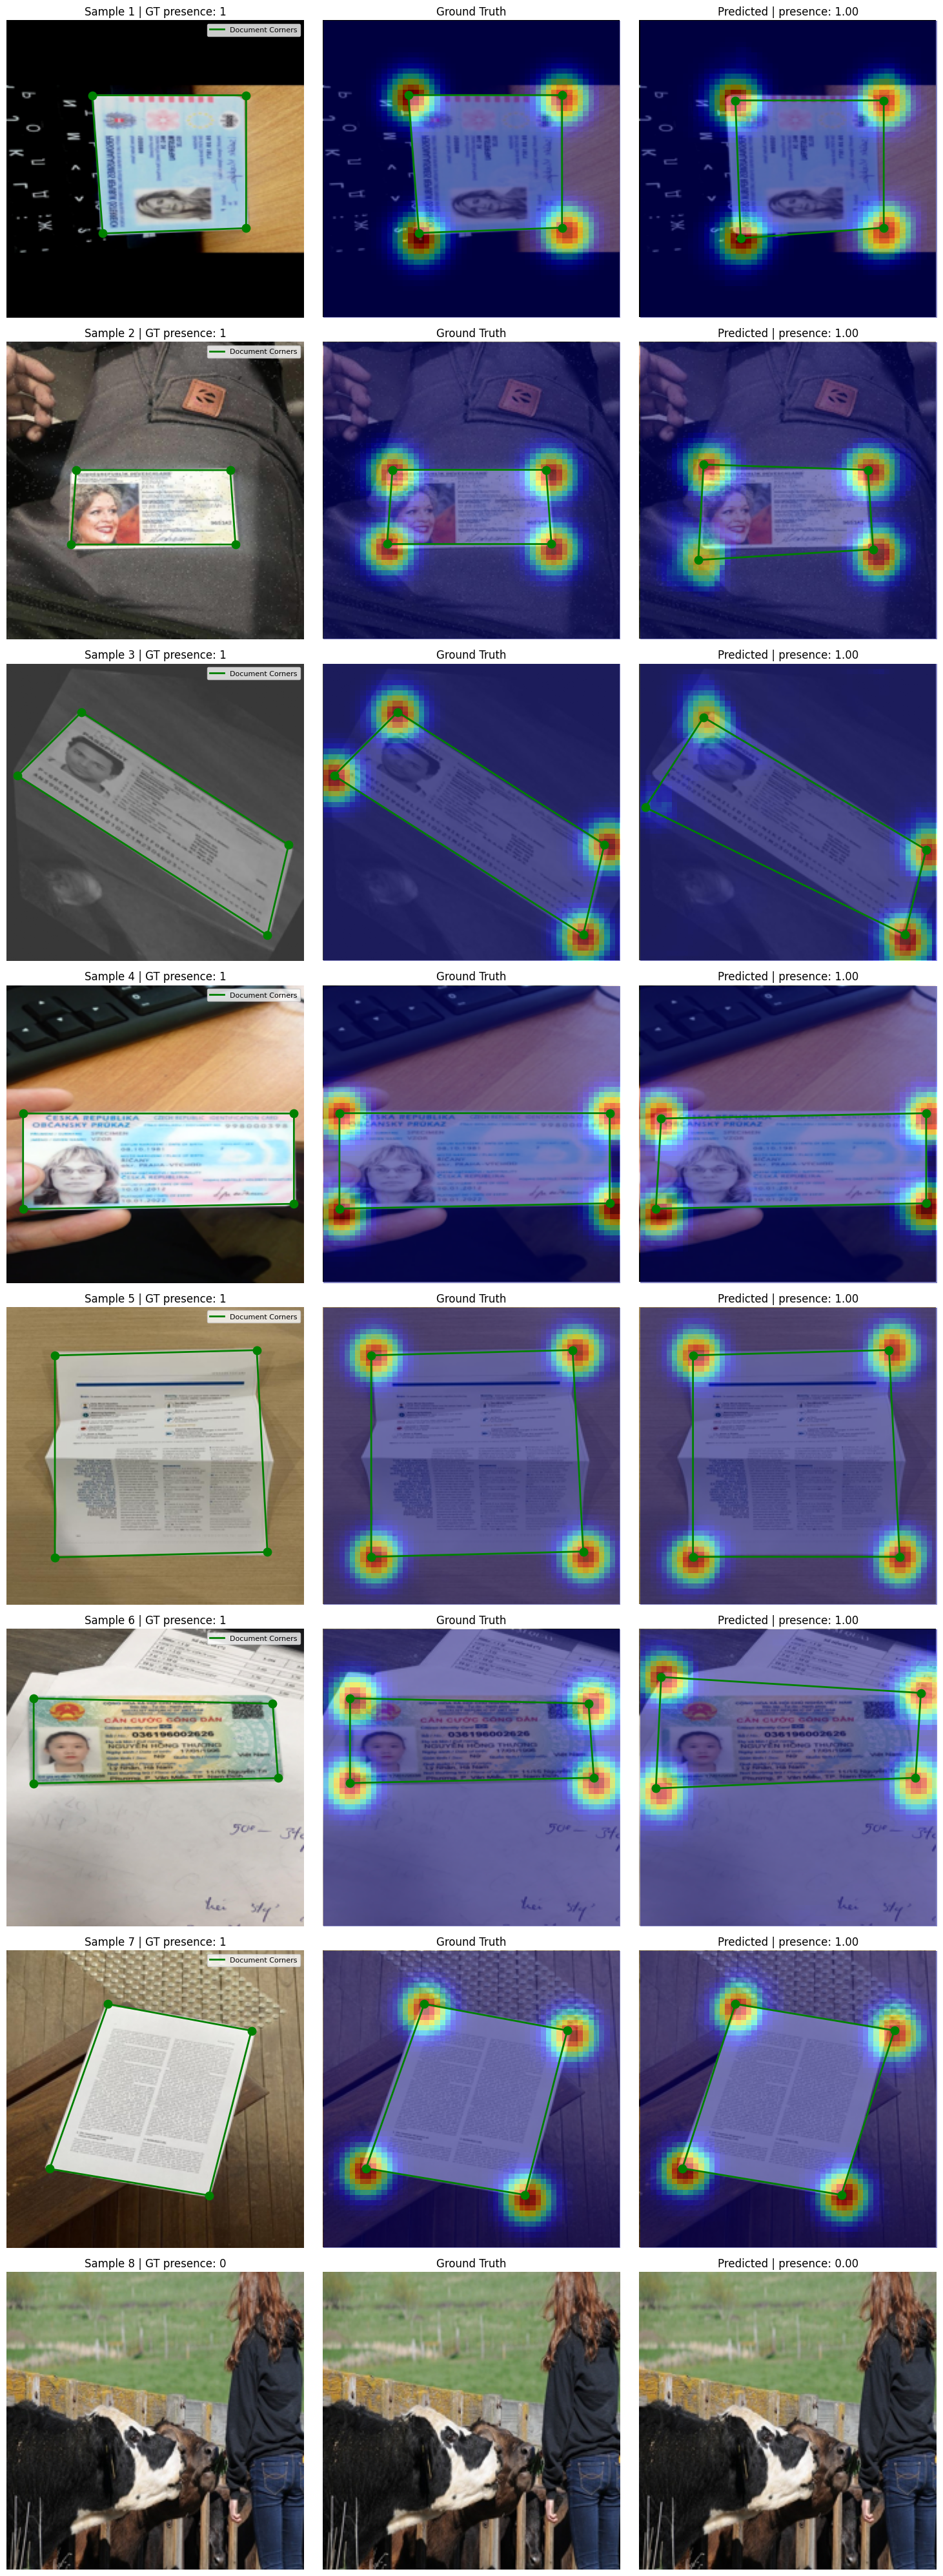

In [17]:
import matplotlib.pyplot as plt
import numpy as np

def extract_corners_from_heatmaps(heatmaps, img_size=IMG_SIZE, hm_size=HEATMAP_SIZE):
    """Extract corner coordinates from heatmaps (4 channels)."""
    corners = []
    for ch in range(4):
        hm = heatmaps[:, :, ch]
        y_idx, x_idx = np.unravel_index(np.argmax(hm), hm.shape)
        # Convert from heatmap coordinates to image coordinates
        x_img = (x_idx / hm_size) * img_size
        y_img = (y_idx / hm_size) * img_size
        corners.append([x_img, y_img])
    return np.array(corners)

def visualize_predicted_heatmaps(model, tf_dataset, num_samples=4):
    """Visualize random samples: ground-truth vs predicted with heatmaps and corners."""
    sample_pool = max(num_samples * 8, 64)
    sampled_ds = tf_dataset.unbatch().shuffle(sample_pool).batch(num_samples)

    for batch_images, (batch_heatmaps, batch_doc_present) in sampled_ds.take(1):
        break

    num_samples = min(num_samples, batch_images.shape[0])
    pred_heatmaps, pred_presence = model.predict(batch_images[:num_samples], verbose=0)

    fig, axes = plt.subplots(num_samples, 3, figsize=(15, 5 * num_samples))
    if num_samples == 1:
        axes = np.expand_dims(axes, axis=0)

    for i in range(num_samples):
        image = batch_images[i].numpy()
        gt_heatmaps = batch_heatmaps[i].numpy()
        gt_present = float(batch_doc_present[i].numpy())
        p_heatmaps = pred_heatmaps[i]
        p_present = float(pred_presence[i])

        gt_combined = np.max(gt_heatmaps, axis=-1)
        pred_combined = np.max(p_heatmaps, axis=-1)

        # Extract corners
        gt_corners = extract_corners_from_heatmaps(gt_heatmaps) if gt_present > 0.5 else None
        pred_corners = extract_corners_from_heatmaps(p_heatmaps) if p_present > 0.5 else None

        ax0, ax1, ax2 = axes[i]

        # Column 0: Original image with GT corners
        ax0.imshow(image)
        if gt_corners is not None:
            # Draw polygon connecting corners
            corners_closed = np.vstack([gt_corners, gt_corners[0]])  # Close the polygon
            ax0.plot(corners_closed[:, 0], corners_closed[:, 1], 'g-', linewidth=2, label='Document Corners')
            ax0.scatter(gt_corners[:, 0], gt_corners[:, 1], c='green', edgecolors='green', s=80, zorder=3)
            ax0.legend(fontsize=8, loc='upper right')
        ax0.set_title(f"Sample {i + 1} | GT presence: {gt_present:.0f}")
        ax0.axis("off")

        # Column 1: GT heatmap with GT corners
        ax1.imshow(image)
        if gt_present > 0.5:
            ax1.imshow(
                gt_combined,
                cmap="jet",
                alpha=0.5,
                extent=[0, IMG_SIZE, IMG_SIZE, 0],
            )
            # Draw polygon connecting corners
            corners_closed = np.vstack([gt_corners, gt_corners[0]])
            ax1.plot(corners_closed[:, 0], corners_closed[:, 1], 'g-', linewidth=2)
            ax1.scatter(gt_corners[:, 0], gt_corners[:, 1], c='green', edgecolors='green', s=80, zorder=3)
        ax1.set_title("Ground Truth")
        ax1.axis("off")

        # Column 2: Predicted heatmap with predicted corners
        ax2.imshow(image)
        if p_present > 0.5:
            ax2.imshow(
                pred_combined,
                cmap="jet",
                alpha=0.5,
                extent=[0, IMG_SIZE, IMG_SIZE, 0],
            )
            # Draw polygon connecting corners
            corners_closed = np.vstack([pred_corners, pred_corners[0]])
            ax2.plot(corners_closed[:, 0], corners_closed[:, 1], 'g-', linewidth=2)
            ax2.scatter(pred_corners[:, 0], pred_corners[:, 1], c='green', edgecolors='green', s=80, zorder=3)
        ax2.set_title(f"Predicted | presence: {p_present:.2f}")
        ax2.axis("off")

    plt.tight_layout()
    plt.show()

# Run after training
visualize_predicted_heatmaps(model, test_ds, num_samples=8)